# 06 · Random Forest – classificação de gravidade e predições

Complementa a regressão logística (notebook 04) com um modelo de **aprendizado de máquina**
(scikit-learn) que estima a probabilidade de um sinistro ser **grave ou fatal**.

| Seção | Conteúdo |
|---|---|
| 1 | Variáveis preditoras (as mesmas da logística + sazonalidade mensal cíclica) |
| 2 | Treino/teste 80/20 estratificado e validação cruzada 5-fold (AUC-ROC) |
| 3 | Métricas: acurácia, precisão, recall, F1, AUC-ROC |
| 4 | Importância **Gini** e importância por **permutação** (checagem) |
| 5 | Matriz de confusão e curva ROC (RF × logística) |
| 6 | Probabilidades **calibradas** por cenário hipotético (rodovia × via urbana, Campinas × Guarulhos) |
| 7 | Comparação com a regressão logística e texto para o TCC (gerado a partir dos resultados) |

In [1]:
import sys
from pathlib import Path
RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))

import warnings; warnings.filterwarnings("ignore")
import polars as pl
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             roc_curve, brier_score_loss)
from IPython.display import Markdown, display
from src import config, viz

viz.tema()
sin = pl.read_parquet(config.DATA_PROCESSED / "sinistros.parquet").to_pandas()
print(f"{len(sin):,} sinistros | grave/fatal: {sin.grave_fatal.mean():.1%} | scikit-learn {sklearn.__version__}")

25,858 sinistros | grave/fatal: 13.3% | scikit-learn 1.9.1


## 1. Variáveis preditoras
Mesmas variáveis da regressão logística (município, tipo de via, período, fim de semana, ano,
modos e tipos de sinistro) + mês codificado de forma cíclica (seno/cosseno), que evita a
"quebra" artificial entre dezembro e janeiro.

In [2]:
base = sin.dropna(subset=["periodo"]).copy()
X = pd.DataFrame({
    "Guarulhos": base.municipio == "GUARULHOS", "Rodovia": base.grupo_via == "RODOVIA",
    "Madrugada": base.periodo == "Madrugada", "Tarde": base.periodo == "Tarde", "Noite": base.periodo == "Noite",
    "Fim de semana": base.fim_semana,
    "Ano 2023": base.ano == 2023, "Ano 2024": base.ano == 2024, "Ano 2025": base.ano == 2025,
    "Motocicleta": base.envolve_moto, "Veículo pesado": base.envolve_pesado,
    "Bicicleta": base.envolve_bicicleta, "Pedestre": base.envolve_pedestre,
    "Capotamento": base.tp_capotamento, "Tombamento": base.tp_tombamento,
    "Colisão frontal": base.tp_colisao_frontal, "Colisão lateral": base.tp_colisao_lateral,
    "Colisão transversal": base.tp_colisao_transv, "Choque": base.tp_choque,
    "Engavetamento": base.tp_engavetamento,
}).astype(float)
X["Mês (seno)"] = np.sin(2 * np.pi * base.mes / 12)
X["Mês (cosseno)"] = np.cos(2 * np.pi * base.mes / 12)
y = base.grave_fatal.astype(int).values
feats = list(X.columns)
print(f"{len(feats)} variáveis | {len(y):,} sinistros | positivos (grave/fatal): {y.mean():.1%}")

22 variáveis | 25,820 sinistros | positivos (grave/fatal): 13.1%


## 2. Treino, teste e validação cruzada
- Divisão **80/20 estratificada** (mesma semente 42 da logística no notebook 04).
- `class_weight="balanced"` compensa o desbalanceamento das classes.
- `max_depth=10` e `min_samples_leaf=20` limitam o sobreajuste.

In [3]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=config.SEED, stratify=y)
params = dict(n_estimators=300, max_depth=10, min_samples_leaf=20, class_weight="balanced",
              random_state=config.SEED, n_jobs=-1)
rf = RandomForestClassifier(**params).fit(X_tr, y_tr)
cv = cross_val_score(RandomForestClassifier(**params), X, y, scoring="roc_auc",
                     cv=StratifiedKFold(5, shuffle=True, random_state=config.SEED))
print(f"Treino: {len(X_tr):,} | Teste: {len(X_te):,}")
print(f"AUC-ROC validação cruzada 5-fold: {cv.mean():.3f} ± {cv.std():.3f}  (folds: {np.round(cv, 3)})")

Treino: 20,656 | Teste: 5,164
AUC-ROC validação cruzada 5-fold: 0.707 ± 0.014  (folds: [0.727 0.692 0.692 0.706 0.718])


## 3. Métricas no conjunto de teste

In [4]:
y_pred = rf.predict(X_te)
y_proba = rf.predict_proba(X_te)[:, 1]
auc_rf = roc_auc_score(y_te, y_proba)
nomes = ["Leve/Sem vítima", "Grave/Fatal"]
print(classification_report(y_te, y_pred, target_names=nomes, digits=3))
print(f"AUC-ROC (teste) = {auc_rf:.3f}")
rep = pd.DataFrame(classification_report(y_te, y_pred, target_names=nomes, output_dict=True)).T.round(3)
viz.salvar_tab(rep, "06_classification_report", index=True)
rep

                 precision    recall  f1-score   support

Leve/Sem vítima      0.918     0.683     0.784      4485
    Grave/Fatal      0.223     0.599     0.325       679

       accuracy                          0.672      5164
      macro avg      0.571     0.641     0.554      5164
   weighted avg      0.827     0.672     0.723      5164

AUC-ROC (teste) = 0.705
  ✔ tabela salva: reports/tables/06_classification_report.csv


,precision,recall,f1-score,support
Leve/Sem vítima,0.918,0.683,0.784,4485.000
Grave/Fatal,0.223,0.599,0.325,679.000
accuracy,0.672,0.672,0.672,0.672
macro avg,0.571,0.641,0.554,5164.000
weighted avg,0.827,0.672,0.723,5164.000


## 4. Importância das variáveis
**Gini (redução média de impureza):** quanto cada variável ajuda a separar as classes nas árvores.
Como a importância Gini favorece variáveis contínuas (aqui, o mês), calculamos também a
**importância por permutação** no teste (queda do AUC ao embaralhar a variável).

In [5]:
fi = pd.DataFrame({"variavel": feats, "gini": rf.feature_importances_})
perm = permutation_importance(rf, X_te, y_te, scoring="roc_auc", n_repeats=10,
                              random_state=config.SEED, n_jobs=-1)
fi["permutacao_auc"] = perm.importances_mean
fi["permutacao_dp"] = perm.importances_std
fi = fi.sort_values("gini", ascending=False).reset_index(drop=True)
viz.salvar_tab(fi.round(5), "06_feature_importance")
fi.round(4)

  ✔ tabela salva: reports/tables/06_feature_importance.csv


,variavel,gini,permutacao_auc,permutacao_dp
0,Motocicleta,0.1292,0.0492,0.0062
1,Pedestre,0.1291,0.0542,0.0053
2,Colisão lateral,0.0997,0.0274,0.0036
3,Choque,0.0883,0.0211,0.0020
4,Veículo pesado,0.0736,0.0166,0.0030
5,Madrugada,0.0679,0.0151,0.0015
6,Rodovia,0.0668,0.0151,0.0021
7,Guarulhos,0.0570,0.0102,0.0035
8,Mês (seno),0.0407,0.0004,0.0005
9,Mês (cosseno),0.0394,-0.0001,0.0006


## 5. Gini, matriz de confusão e curva ROC (mesmo layout do dashboard)
A curva ROC inclui a regressão logística ajustada nos **mesmos** dados de treino, para comparação.

  ✔ figura salva: reports/figures/06_rf_metricas.png


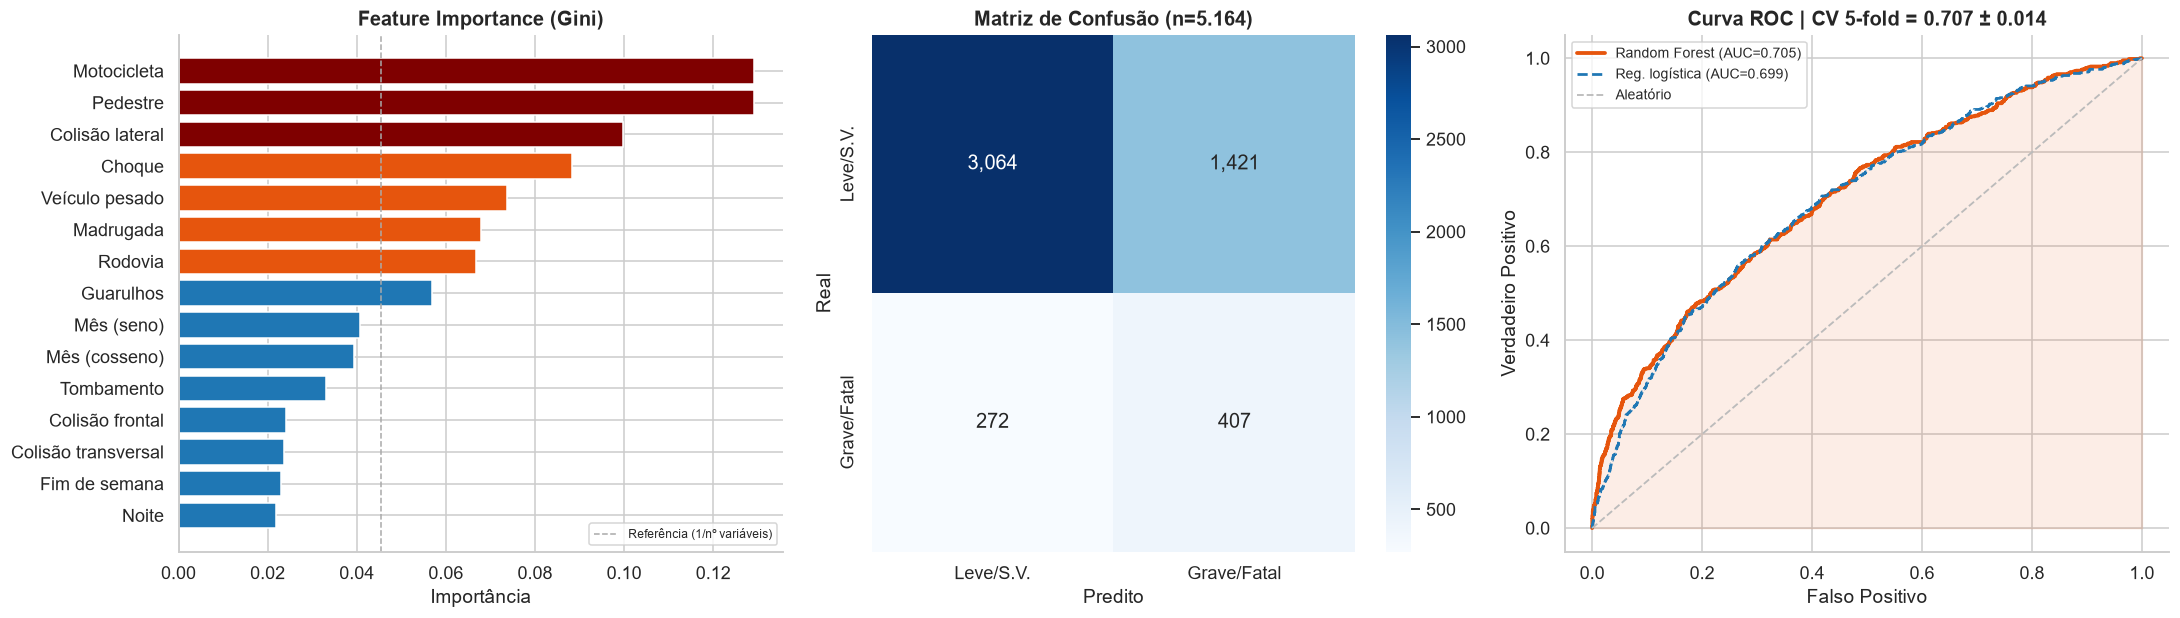

In [6]:
logit = LogisticRegression(max_iter=2000).fit(X_tr, y_tr)
p_log = logit.predict_proba(X_te)[:, 1]
auc_log = roc_auc_score(y_te, p_log)

fig, axes = plt.subplots(1, 3, figsize=(20, 5.8))
top = fi.head(15)
cores = ["#7f0000" if i < 3 else "#e6550d" if i < 7 else "#1f77b4" for i in range(len(top))]
axes[0].barh(top.variavel[::-1], top.gini[::-1], color=cores[::-1])
axes[0].axvline(1 / len(feats), ls="--", color="#aaa", lw=1, label="Referência (1/nº variáveis)")
axes[0].set(title="Feature Importance (Gini)", xlabel="Importância", ylabel=""); axes[0].legend(fontsize=8)

cm = confusion_matrix(y_te, y_pred)
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", xticklabels=["Leve/S.V.", "Grave/Fatal"],
            yticklabels=["Leve/S.V.", "Grave/Fatal"], annot_kws={"size": 13}, ax=axes[1])
axes[1].set(title=f"Matriz de Confusão (n={len(y_te):,})".replace(",", "."), xlabel="Predito", ylabel="Real")

fpr, tpr, _ = roc_curve(y_te, y_proba)
fl, tl, _ = roc_curve(y_te, p_log)
axes[2].plot(fpr, tpr, lw=2.5, color="#e6550d", label=f"Random Forest (AUC={auc_rf:.3f})")
axes[2].plot(fl, tl, lw=1.8, color="#1f77b4", ls="--", label=f"Reg. logística (AUC={auc_log:.3f})")
axes[2].plot([0, 1], [0, 1], "--", color="#bbb", lw=1.2, label="Aleatório")
axes[2].fill_between(fpr, tpr, alpha=.1, color="#e6550d")
axes[2].set(title=f"Curva ROC | CV 5-fold = {cv.mean():.3f} ± {cv.std():.3f}",
            xlabel="Falso Positivo", ylabel="Verdadeiro Positivo"); axes[2].legend(fontsize=9)
plt.tight_layout(); viz.salvar_fig(fig, "06_rf_metricas"); plt.show()

  ✔ figura salva: reports/figures/06_importancia_permutacao.png


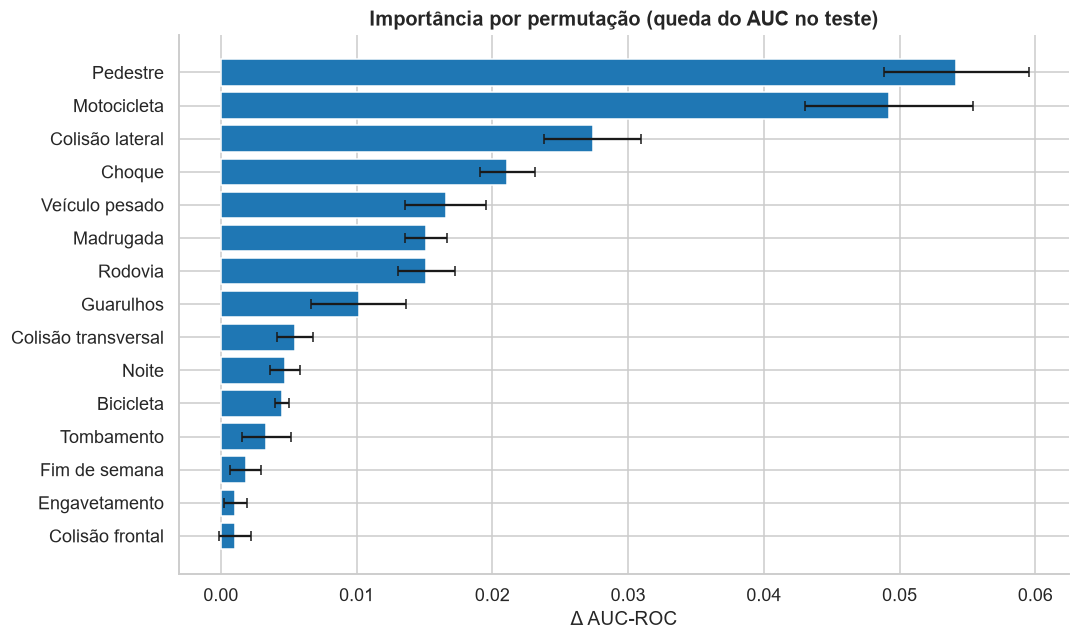

In [7]:
fig, ax = plt.subplots(figsize=(10, 6))
d = fi.sort_values("permutacao_auc").tail(15)
ax.barh(d.variavel, d.permutacao_auc, xerr=d.permutacao_dp, color="#1f77b4", capsize=3)
ax.set(title="Importância por permutação (queda do AUC no teste)", xlabel="Δ AUC-ROC", ylabel="")
plt.tight_layout(); viz.salvar_fig(fig, "06_importancia_permutacao"); plt.show()

## 6. Probabilidade por cenário hipotético
O RF com `class_weight="balanced"` produz **escores inflados** (não são probabilidades reais).
Por isso os cenários usam o RF **calibrado** (`CalibratedClassifierCV`, isotônico, 5 folds),
cujas saídas podem ser lidas como probabilidade. Cada cenário é a média das previsões nos 12
meses de 2024 (sazonalidade neutra). Linha tracejada = taxa observada de graves/fatais na base.

In [8]:
rf_cal = CalibratedClassifierCV(RandomForestClassifier(**params), method="isotonic", cv=5).fit(X_tr, y_tr)
p_cal = rf_cal.predict_proba(X_te)[:, 1]
print(f"Brier score: RF bruto = {brier_score_loss(y_te, y_proba):.4f} | RF calibrado = {brier_score_loss(y_te, p_cal):.4f}")
print(f"AUC RF calibrado (teste) = {roc_auc_score(y_te, p_cal):.3f}")

def prob(**kw):
    linhas = []
    for mes in range(1, 13):
        r = dict.fromkeys(feats, 0.0)
        r.update({"Ano 2024": 1.0, "Mês (seno)": np.sin(2 * np.pi * mes / 12), "Mês (cosseno)": np.cos(2 * np.pi * mes / 12)})
        for k, v in kw.items():
            assert k in feats, f"variável inexistente no modelo: {k}"
            r[k] = float(v)
        linhas.append(r)
    return round(rf_cal.predict_proba(pd.DataFrame(linhas)[feats])[:, 1].mean() * 100, 1)

G = {"Guarulhos": 1}; R = {"Rodovia": 1}
cenarios = [
    ("ROD · Manhã, dia útil – Campinas", prob(**R)),
    ("ROD · Manhã, dia útil – Guarulhos", prob(**R, **G)),
    ("ROD · Noite, veículo pesado – Campinas", prob(**R, Noite=1, **{"Veículo pesado": 1})),
    ("ROD · Madrugada, moto – Guarulhos", prob(**R, **G, Madrugada=1, Motocicleta=1)),
    ("ROD · Pedestre (atropelamento), noite – Campinas", prob(**R, Noite=1, Pedestre=1)),
    ("ROD · Capotamento, madrugada – Campinas", prob(**R, Madrugada=1, Capotamento=1)),
    ("ROD · Capotamento, madrugada – Guarulhos", prob(**R, **G, Madrugada=1, Capotamento=1)),
    ("URB · Manhã, dia útil – Campinas", prob()),
    ("URB · Manhã, dia útil – Guarulhos", prob(**G)),
    ("URB · Fim de semana, noite, moto – Guarulhos", prob(**G, Noite=1, Motocicleta=1, **{"Fim de semana": 1})),
    ("URB · Pedestre (atropelamento), noite – Campinas", prob(Noite=1, Pedestre=1)),
    ("URB · Bicicleta, noite – Guarulhos", prob(**G, Noite=1, Bicicleta=1)),
    ("URB · Capotamento, madrugada – Campinas", prob(Madrugada=1, Capotamento=1)),
]
pred = pd.DataFrame(cenarios, columns=["Cenário", "P(grave ou fatal) %"])
viz.salvar_tab(pred, "06_predicoes_cenarios")
media = y.mean() * 100
pred

Brier score: RF bruto = 0.2142 | RF calibrado = 0.1039
AUC RF calibrado (teste) = 0.706


  ✔ tabela salva: reports/tables/06_predicoes_cenarios.csv


,Cenário,P(grave ou fatal) %
0,"ROD · Manhã, dia útil – Campinas",7.2
1,"ROD · Manhã, dia útil – Guarulhos",6.0
2,"ROD · Noite, veículo pesado – Campinas",19.3
3,"ROD · Madrugada, moto – Guarulhos",21.6
4,"ROD · Pedestre (atropelamento), noite – Campinas",78.2
5,"ROD · Capotamento, madrugada – Campinas",16.7
6,"ROD · Capotamento, madrugada – Guarulhos",13.2
7,"URB · Manhã, dia útil – Campinas",3.4
8,"URB · Manhã, dia útil – Guarulhos",3.9
9,"URB · Fim de semana, noite, moto – Guarulhos",14.9


  ✔ figura salva: reports/figures/06_predicoes_cenarios.png


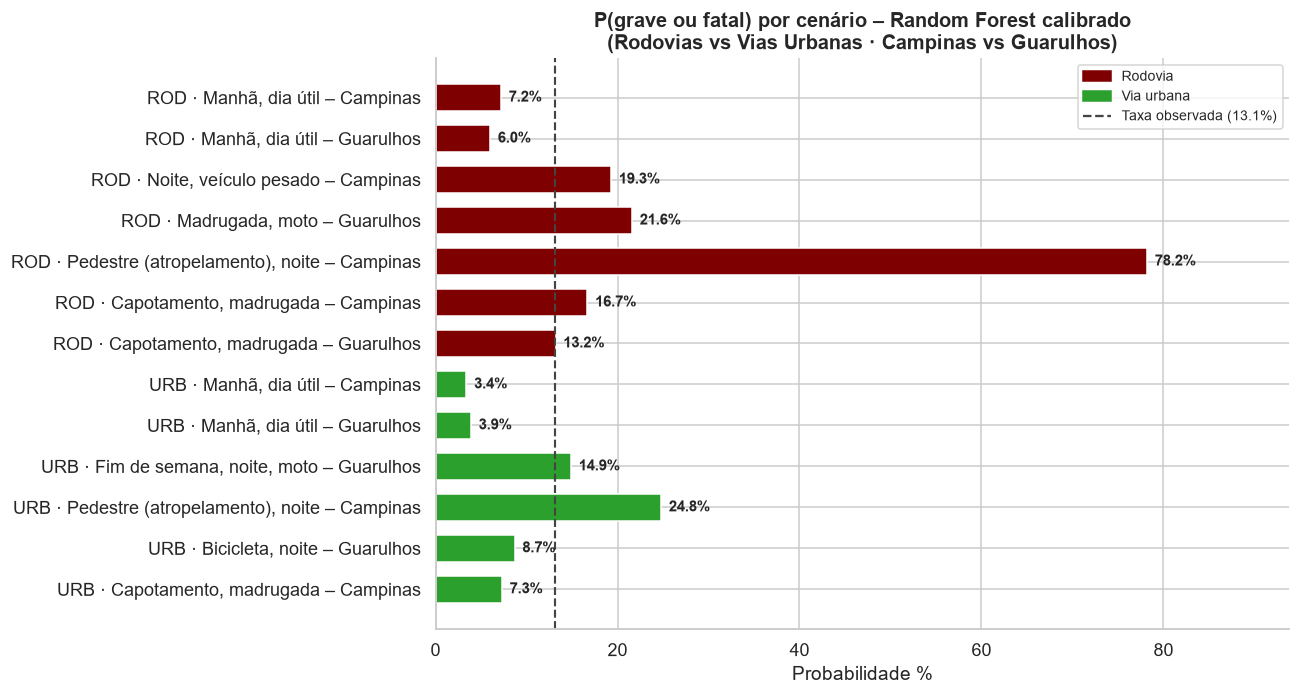

In [9]:
fig, ax = plt.subplots(figsize=(12, 6.5))
cores = ["#7f0000" if c.startswith("ROD") else "#2ca02c" for c in pred["Cenário"]]
bars = ax.barh(pred["Cenário"][::-1], pred["P(grave ou fatal) %"][::-1], color=cores[::-1], height=.65)
ax.bar_label(bars, fmt="%.1f%%", padding=5, fontsize=10, fontweight="bold")
ax.axvline(media, ls="--", color="#444", lw=1.4, label=f"Taxa observada na base ({media:.1f}%)")
ax.set(title="P(grave ou fatal) por cenário – Random Forest calibrado\n(Rodovias vs Vias Urbanas · Campinas vs Guarulhos)",
       xlabel="Probabilidade %", ylabel="", xlim=(0, max(pred["P(grave ou fatal) %"].max() * 1.2, media * 1.5)))
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#7f0000", label="Rodovia"), Patch(color="#2ca02c", label="Via urbana"),
                   plt.Line2D([], [], ls="--", color="#444", label=f"Taxa observada ({media:.1f}%)")], fontsize=9)
plt.tight_layout(); viz.salvar_fig(fig, "06_predicoes_cenarios"); plt.show()

## 7. Random Forest × Regressão Logística

In [10]:
log04 = pd.read_csv(config.TAB_DIR / "04_auc_logistica.csv")
comp = pd.DataFrame([
    {"modelo": "Regressão logística (statsmodels, nb 04)", "auc_teste": log04.auc_teste[0], "cv_auc": np.nan, "cv_dp": np.nan},
    {"modelo": "Random Forest", "auc_teste": round(auc_rf, 4), "cv_auc": round(cv.mean(), 4), "cv_dp": round(cv.std(), 4)},
])
viz.salvar_tab(comp, "06_metricas_resumo")
comp

  ✔ tabela salva: reports/tables/06_metricas_resumo.csv


,modelo,auc_teste,cv_auc,cv_dp
0,"Regressão logística (statsmodels, nb 04)",0.6990,NaN,NaN
1,Random Forest,0.7046,0.7068,0.0141


| Critério | Regressão Logística | Random Forest |
|---|---|---|
| Objetivo | Explicar associações (Odds Ratio) | Predizer casos novos |
| Interpretabilidade | Alta – OR com IC 95% e p-valor | Média – importância Gini/permutação |
| Pressupostos | Linearidade no logit, independência | Não paramétrico |
| Uso no TCC | Resultados e discussão dos fatores de risco | Capacidade preditiva e cenários |

### Texto para o TCC (preenchido automaticamente com os resultados acima)

In [11]:
top3 = fi.head(3)
top3p = fi.sort_values("permutacao_auc", ascending=False).head(3)
rot = pred.set_index("Cenário")["P(grave ou fatal) %"]
br = lambda v, d=3: f"{v:.{d}f}".replace(".", ",")   # vírgula decimal (ABNT)
txt_met = (
    f"> **Metodologia.** Complementarmente à regressão logística, aplicou-se um modelo Random Forest "
    f"(BREIMAN, 2001), implementado com scikit-learn {sklearn.__version__} (PEDREGOSA et al., 2011). "
    f"O modelo classificou os {len(y):_} sinistros com vítima de Campinas e Guarulhos (2022–2025) em "
    f"graves/fatais ou leves/sem vítima informada, utilizando {len(feats)} variáveis preditoras "
    f"(município, tipo de via, período do dia, fim de semana, ano, mês, veículos/usuários envolvidos e "
    f"tipo de sinistro). Usou-se divisão treino/teste 80/20 estratificada, 300 árvores com profundidade "
    f"máxima 10, mínimo de 20 observações por folha e pesos balanceados entre classes. O desempenho foi "
    f"avaliado pela AUC-ROC no teste e em validação cruzada estratificada de 5 folds; as probabilidades "
    f"por cenário foram obtidas após calibração isotônica.").replace("_", ".")
txt_res = (
    f"> **Resultados.** O Random Forest obteve AUC-ROC de {br(auc_rf)} no conjunto de teste "
    f"(validação cruzada 5-fold: {br(cv.mean())} ± {br(cv.std())}), frente a {br(log04.auc_teste[0])} da regressão "
    f"logística, indicando capacidade discriminativa {'moderada' if auc_rf >= 0.7 else 'modesta'}. "
    f"As variáveis de maior importância Gini foram {top3.variavel.iloc[0]} ({br(top3.gini.iloc[0])}), "
    f"{top3.variavel.iloc[1]} ({br(top3.gini.iloc[1])}) e {top3.variavel.iloc[2]} ({br(top3.gini.iloc[2])}); "
    f"pela importância por permutação, destacaram-se {', '.join(top3p.variavel)}. "
    f"Nos cenários hipotéticos, a maior probabilidade estimada de sinistro grave ou fatal foi "
    f"'{rot.idxmax()}' ({br(rot.max(), 1)}%) e a menor, '{rot.idxmin()}' ({br(rot.min(), 1)}%), "
    f"para uma taxa observada de {br(media, 1)}%.")
display(Markdown(txt_met))
display(Markdown(txt_res))
_ = (config.TAB_DIR / "06_texto_tcc.md").write_text(txt_met + "\n\n" + txt_res, encoding="utf-8")

> **Metodologia.** Complementarmente à regressão logística, aplicou-se um modelo Random Forest (BREIMAN, 2001), implementado com scikit-learn 1.9.1 (PEDREGOSA et al., 2011). O modelo classificou os 25.820 sinistros com vítima de Campinas e Guarulhos (2022–2025) em graves/fatais ou leves/sem vítima informada, utilizando 22 variáveis preditoras (município, tipo de via, período do dia, fim de semana, ano, mês, veículos/usuários envolvidos e tipo de sinistro). Usou-se divisão treino/teste 80/20 estratificada, 300 árvores com profundidade máxima 10, mínimo de 20 observações por folha e pesos balanceados entre classes. O desempenho foi avaliado pela AUC-ROC no teste e em validação cruzada estratificada de 5 folds; as probabilidades por cenário foram obtidas após calibração isotônica.

> **Resultados.** O Random Forest obteve AUC-ROC de 0,705 no conjunto de teste (validação cruzada 5-fold: 0,707 ± 0,014), frente a 0,699 da regressão logística, indicando capacidade discriminativa moderada. As variáveis de maior importância Gini foram Motocicleta (0,129), Pedestre (0,129) e Colisão lateral (0,100); pela importância por permutação, destacaram-se Pedestre, Motocicleta, Colisão lateral. Nos cenários hipotéticos, a maior probabilidade estimada de sinistro grave ou fatal foi 'ROD · Pedestre (atropelamento), noite – Campinas' (78,2%) e a menor, 'URB · Manhã, dia útil – Campinas' (3,4%), para uma taxa observada de 13,1%.

### Referências (ABNT)
BREIMAN, Leo. Random forests. **Machine Learning**, v. 45, n. 1, p. 5–32, 2001.

PEDREGOSA, F. et al. Scikit-learn: Machine learning in Python. **Journal of Machine Learning
Research**, v. 12, p. 2825–2830, 2011.

SÃO PAULO (Estado). Infosiga SP – Sistema de Informações Gerenciais de Sinistros de Trânsito.
Dados abertos, 2022–2025.